# Métodos del mapa de investigación

Monitoreo indirecto de puentes con smartphones (*drive-by*): explicación de los **métodos** que aparecen en el mapa de investigación. El notebook sigue el orden del mapa, pero solo contiene información de métodos; solo aparecen los encabezados que ya tienen algún método.

<a id="indice"></a>
## Índice

- [2 Modal identification](#modal-identification)
  - [2.2 Mode shapes](#mode-shapes)
    - [Paso 1 · Signal decomposition](#mode-shapes-paso-1)
      - [Wavelet transform (SSWT)](#wavelet-sswt)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import Wavelet, cwt, ssq_cwt
from ssqueezepy.experimental import scale_to_freq

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def morlet(t, w0=6.0):
    """Complex Morlet mother wavelet (Eq. 1): oscillation times a Gaussian bell."""
    return np.pi ** -0.25 * np.exp(1j * w0 * t) * np.exp(-t ** 2 / 2)


def scale_for_freq(f, w0=6.0):
    """Scale a whose wavelet oscillates at frequency f in Hz (Eq. 2 solved for a)."""
    return w0 / (2 * np.pi * f)


def scaled_wavelet(t, a, b, w0=6.0):
    """Mother wavelet stretched by scale a and shifted to time b (kernel of Eq. 3)."""
    return morlet((t - b) / a, w0) / np.sqrt(a)

<a id="modal-identification"></a>
# 2 Modal identification

<a id="mode-shapes"></a>
## 2.2 Mode shapes

<a id="mode-shapes-paso-1"></a>
### Paso 1 · Signal decomposition

<a id="wavelet-sswt"></a>
#### Wavelet transform (SSWT)

SSWT: *synchrosqueezed wavelet transform*, transformada wavelet sincro-comprimida. Parte de la CWT (*continuous wavelet transform*, transformada wavelet continua).

**Qué es**

- La transformada wavelet descompone una señal en frecuencias, como Fourier, pero además dice **en qué momento** aparece cada frecuencia.
- La versión sincro-comprimida (SSWT) concentra mejor la energía en cada frecuencia, por lo que el mapa sale más nítido.

**Para qué se aplica**

- En señales **cortas o no estacionarias**, donde las frecuencias o sus amplitudes cambian en el tiempo.
- En *drive-by*: para ver cómo cambia la amplitud de una frecuencia del puente mientras el carro avanza, y con eso construir la forma modal.

**Cómo funciona**

1. Se escoge una **wavelet madre**: una onda corta que oscila y se apaga hacia los lados. La más usada en vibraciones es la Morlet.
2. Para cada frecuencia, la wavelet se **estira o se comprime** y se coloca en cada instante de la señal.
3. En cada posición se **multiplica punto por punto** con la señal y se suma: si la señal oscila a esa frecuencia en ese momento, el resultado es grande; si no, es casi cero.
4. Así se llena un **mapa frecuencia contra tiempo**, donde cada celda es una amplitud.

*Paso 1: la wavelet madre Morlet.*

$$\psi(t)=\pi^{-1/4}\,e^{i\omega_0 t}\,e^{-t^{2}/2} \tag{1}$$

- $\psi(t)$: wavelet madre Morlet (valor complejo) en el instante $t$.
- $t$: tiempo de la wavelet madre, en s.
- $i$: unidad imaginaria.
- $\omega_0$: frecuencia central (adimensional); fija cuántas oscilaciones caben dentro de la campana. Valor típico: $\omega_0 \approx 6$.
- $e^{i\omega_0 t}=\cos(\omega_0 t)+i\,\sin(\omega_0 t)$: la **oscilación**.
- $e^{-t^{2}/2}$: la **campana** gaussiana que apaga la oscilación hacia los lados.
- $\pi^{-1/4}$: constante para que la wavelet tenga energía unitaria.

En palabras: una onda que oscila a $\omega_0$ multiplicada por una campana; oscila en el centro y se apaga hacia los lados.

*Paso 2: estirar o comprimir.* La wavelet se usa como $\psi\!\left(\frac{t-b}{a}\right)$: la escala $a$ la estira o la comprime y $b$ la desplaza en el tiempo. La frecuencia a la que oscila depende de la escala:

$$f=\frac{\omega_0}{2\pi a} \tag{2}$$

- $f$: frecuencia a la que oscila la wavelet estirada, en Hz.
- $a$: escala, en s; $a>1$ estira la wavelet y $a<1$ la comprime.
- $\omega_0$: frecuencia central de la Morlet (Ec. 1).
- $2\pi$: pasa de radianes por segundo a ciclos por segundo (Hz).

En palabras: escala grande = wavelet estirada = frecuencia baja; escala pequeña = wavelet comprimida = frecuencia alta.

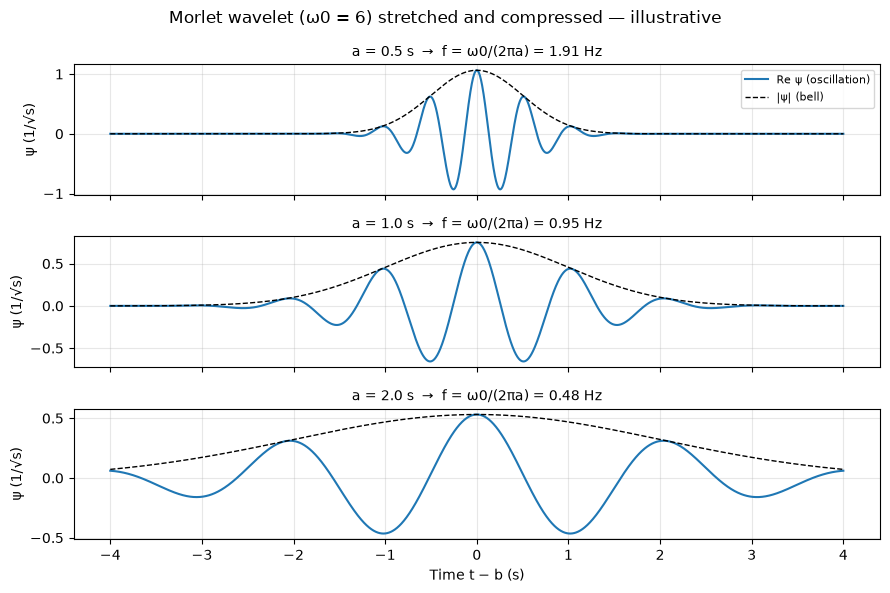

In [2]:
# Real part of the Morlet wavelet at three scales (illustrative)
w0 = 6.0
t = np.linspace(-4, 4, 2000)            # time around the wavelet center, s
scales = [0.5, 1.0, 2.0]                # scale a, s

fig, axes = plt.subplots(len(scales), 1, figsize=(9, 6), sharex=True)
for ax, a in zip(axes, scales):
    psi = scaled_wavelet(t, a, b=0.0, w0=w0)
    f = w0 / (2 * np.pi * a)            # Eq. 2
    ax.plot(t, psi.real, color="C0", label="Re ψ (oscillation)")
    ax.plot(t, np.abs(psi), "k--", lw=1, label="|ψ| (bell)")
    ax.set_ylabel("ψ (1/√s)")
    ax.set_title(f"a = {a} s  →  f = ω0/(2πa) = {f:.2f} Hz", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time t − b (s)")
fig.suptitle("Morlet wavelet (ω0 = 6) stretched and compressed — illustrative")
fig.tight_layout()
plt.show()

**Figura 1.** Parte real de la wavelet Morlet a tres escalas (ilustrativo): con $a$ pequeña la wavelet se comprime y oscila rápido (frecuencia alta); con $a$ grande se estira y oscila lento (frecuencia baja). La línea discontinua es la campana que la apaga hacia los lados.

*Paso 3: multiplicar y sumar.* Para una escala $a$ y un instante $b$, el coeficiente wavelet es:

$$W(a,b)=\frac{1}{\sqrt{a}}\int_{-\infty}^{\infty} x(t)\,\psi^{*}\!\left(\frac{t-b}{a}\right)dt \tag{3}$$

- $W(a,b)$: coeficiente wavelet (complejo) en la escala $a$ y el instante $b$; $|W(a,b)|$ es la **amplitud** de esa celda del mapa.
- $x(t)$: señal medida.
- $\psi$: wavelet madre (Ec. 1); $^{*}$ indica el conjugado complejo.
- $a$: escala, en s (fija la frecuencia, Ec. 2).
- $b$: desplazamiento en el tiempo: instante donde se centra la wavelet, en s.
- $1/\sqrt{a}$: normalización para que la wavelet tenga la misma energía en todas las escalas.
- $\int \dots\, dt$: multiplicar punto por punto la señal por la wavelet y sumar.

En palabras: mide cuánto se parece la señal, alrededor del instante $b$, a una oscilación de la frecuencia que corresponde a la escala $a$.

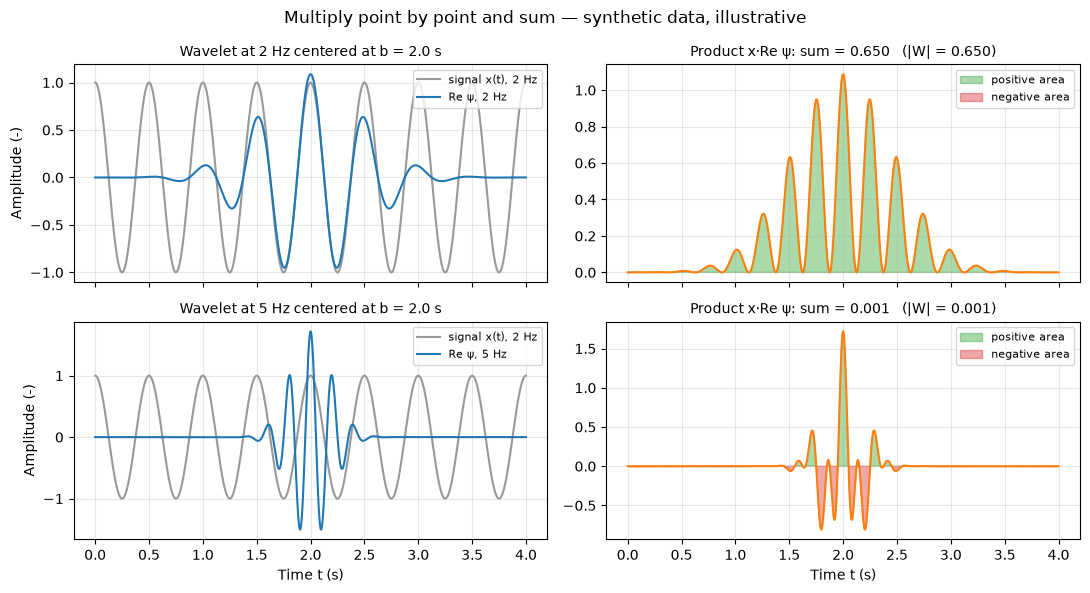

In [3]:
# "Multiply and sum": cosine at 2 Hz vs wavelets at 2 Hz and 5 Hz (illustrative)
dt = 0.001
t = np.arange(0, 4, dt)                 # time, s
f_signal = 2.0                          # signal frequency, Hz
x = np.cos(2 * np.pi * f_signal * t)
b = 2.0                                 # wavelet center, s

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for row, f_wav in enumerate([2.0, 5.0]):
    a = scale_for_freq(f_wav, w0=6.0)
    psi = scaled_wavelet(t, a, b, w0=6.0)
    product = x * psi.real
    total = product.sum() * dt                       # real part of Eq. 3
    W = (x * np.conj(psi)).sum() * dt                # full complex Eq. 3
    ax_l, ax_r = axes[row]
    ax_l.plot(t, x, color="0.6", label="signal x(t), 2 Hz")
    ax_l.plot(t, psi.real, color="C0", label=f"Re ψ, {f_wav:.0f} Hz")
    ax_l.set_ylabel("Amplitude (-)")
    ax_l.set_title(f"Wavelet at {f_wav:.0f} Hz centered at b = {b} s", fontsize=10)
    ax_l.legend(loc="upper right", fontsize=8)
    ax_r.plot(t, product, color="C1")
    ax_r.fill_between(t, product, where=product > 0, color="C2", alpha=0.4, label="positive area")
    ax_r.fill_between(t, product, where=product < 0, color="C3", alpha=0.4, label="negative area")
    ax_r.set_title(f"Product x·Re ψ: sum = {total:.3f}   (|W| = {abs(W):.3f})", fontsize=10)
    ax_r.legend(loc="upper right", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Time t (s)")
fig.suptitle("Multiply point by point and sum — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 2.** Multiplicar y sumar (ilustrativo, datos sintéticos): con la wavelet a la misma frecuencia de la señal (2 Hz, arriba) el producto es casi siempre positivo y la suma es grande; con la wavelet a otra frecuencia (5 Hz, abajo) el producto alterna signo, las áreas se cancelan y la suma es casi cero.

- La suma de la gráfica usa solo la parte real de $\psi$; $|W|$ usa la wavelet compleja completa (Ec. 3). Con la wavelet compleja la amplitud $|W|$ no depende de si la wavelet queda en fase con la señal.

*Paso 4: el mapa.* Repetir la Ec. 3 para muchas escalas $a$ (frecuencias, Ec. 2) y muchos instantes $b$ llena el mapa $|W(a,b)|$. En la CWT la energía de una frecuencia queda **repartida** en una franja ancha de escalas vecinas. La SSWT la reasigna en dos pasos:

$$\omega(a,b)=\frac{-i\,\partial_b W(a,b)}{W(a,b)} \tag{4}$$

- $\omega(a,b)$: frecuencia instantánea de la celda $(a,b)$, en rad/s: la frecuencia a la que realmente oscila la señal en esa celda.
- $\partial_b W(a,b)$: derivada del coeficiente respecto al tiempo $b$.
- $W(a,b)$: coeficiente wavelet (Ec. 3).
- $i$: unidad imaginaria.

En palabras: la fase de $W$ gira a la velocidad de la oscilación de la señal; derivarla en el tiempo da esa frecuencia, aunque la celda esté en una escala vecina.

$$T(f_l,b)=\sum_{a\,:\;\omega(a,b)/2\pi\,\approx\,f_l} W(a,b) \tag{5}$$

- $T(f_l,b)$: valor del mapa sincro-comprimido en la frecuencia $f_l$ (Hz) y el instante $b$.
- $f_l$: cada una de las frecuencias (filas) del mapa nuevo.
- La suma recorre solo las escalas $a$ cuya frecuencia instantánea (Ec. 4, pasada a Hz) cae en $f_l$.
- Expresión conceptual: se omiten las constantes de normalización.

En palabras: la energía de todas las celdas que "dicen" oscilar a $f_l$ se junta en la fila $f_l$; la franja ancha de la CWT se comprime en una línea delgada, y por eso el mapa sale más nítido.

**Ejemplo sintético.** Un carro cruza una viga simplemente apoyada de $L=100$ m a $v=20$ m/s (cruce de 5 s). Mide la vibración del puente en el segundo modo, con $f=1.3$ Hz y forma modal $\phi(x)=\sin(2\pi x/L)$:

$x(t)=|\phi(v\,t)|\cos(2\pi f t)+\text{ruido}$

- La amplitud que ve el carro sube y baja según la forma modal en el punto donde está.
- El eje de tiempo se pasa a posición con $x = v\,t$ (lo que en la práctica da el GPS; ver el apartado siguiente).
- Se usa la Morlet analítica de `ssqueezepy` con $\omega_0 = 3$ (en `ssqueezepy`, `mu`) en vez de 6: la wavelet es más corta y sigue mejor los cambios de amplitud en un cruce de solo 5 s, a cambio de menos resolución en frecuencia. Es una elección para este ejemplo, no un valor del artículo.

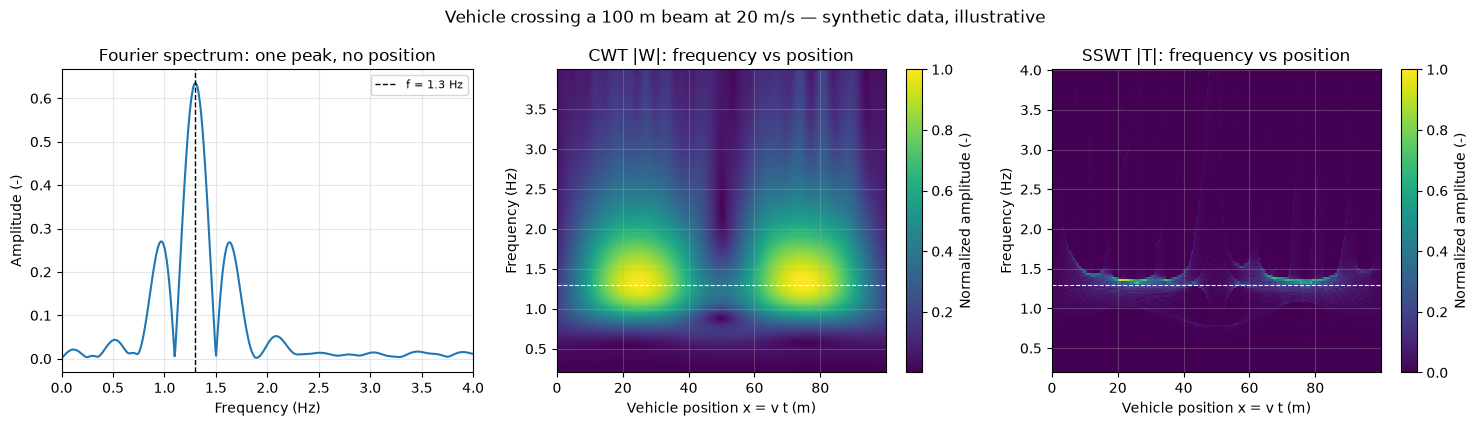

In [4]:
# Synthetic drive-by signal: vehicle crossing a 100 m simply supported beam
L = 100.0                               # span length, m
v = 20.0                                # vehicle speed, m/s
f_mode = 1.3                            # frequency of mode 2, Hz
fs = 100.0                              # sampling rate, Hz
noise_std = 0.1                         # noise standard deviation (-)

t = np.arange(0, L / v, 1 / fs)         # time, s
pos = v * t                             # vehicle position, m (x = v t)
phi_true = np.sin(2 * np.pi * pos / L)  # mode 2 shape
x = np.abs(phi_true) * np.cos(2 * np.pi * f_mode * t) + noise_std * rng.standard_normal(t.size)

# Fourier amplitude spectrum (zero-padded for a smooth curve)
n_fft = 2 ** 14
spec = np.abs(np.fft.rfft(x, n=n_fft)) * 2 / t.size
freqs_fft = np.fft.rfftfreq(n_fft, 1 / fs)

# CWT and SSWT with the analytic Morlet wavelet
wavelet = Wavelet(("morlet", {"mu": 3}))
Wx, scales_cwt = cwt(x, wavelet, fs=fs, nv=32, padtype="zero")
freqs_cwt = scale_to_freq(scales_cwt, wavelet, N=2 ** 14, fs=fs)   # Eq. 2 for this wavelet
Tx, _, freqs_ssq, _ = ssq_cwt(x, wavelet, fs=fs, nv=32, padtype="zero")

f_max = 4.0                             # upper frequency shown, Hz
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(freqs_fft, spec, color="C0")
axes[0].axvline(f_mode, color="k", ls="--", lw=1, label=f"f = {f_mode} Hz")
axes[0].set_xlim(0, f_max)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Amplitude (-)")
axes[0].set_title("Fourier spectrum: one peak, no position")
axes[0].legend(fontsize=8)

for ax, Z, fr, name in [(axes[1], Wx, freqs_cwt, "CWT |W|"), (axes[2], Tx, freqs_ssq, "SSWT |T|")]:
    A = np.abs(Z) / np.abs(Z).max()     # normalized amplitude
    keep = fr <= f_max
    mesh = ax.pcolormesh(pos, fr[keep], A[keep], shading="auto", cmap="viridis")
    ax.axhline(f_mode, color="w", ls="--", lw=0.8)
    ax.set_xlabel("Vehicle position x = v t (m)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(f"{name}: frequency vs position")
    fig.colorbar(mesh, ax=ax, label="Normalized amplitude (-)")
fig.suptitle("Vehicle crossing a 100 m beam at 20 m/s — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 3.** Señal sintética de un carro que cruza una viga de 100 m (ilustrativo): el espectro de Fourier (izquierda) solo muestra un pico cerca de 1.3 Hz, sin decir dónde está; la CWT (centro) muestra esa frecuencia a lo largo de la posición, pero en una franja ancha; la SSWT (derecha) la concentra en una línea delgada y se ve dónde la amplitud crece o cae a cero.

- En los dos mapas la amplitud baja casi a cero en $x \approx 50$ m: ahí está el nodo del segundo modo.
- Fourier no puede mostrarlo porque promedia toda la señal; la wavelet sí, porque mira la señal por ventanas.
- La línea de la SSWT queda ligeramente por encima de 1.3 Hz (≈ 1.35 Hz); por eso, para la forma modal se promedia una banda alrededor de la frecuencia y no una sola fila del mapa.

**Cómo se usa para la forma modal**

- Con el **GPS** se cambia el tiempo por la posición del carro: $x = v\,t$ si la velocidad es constante; en general, la posición GPS en cada instante.
- Se toma la **franja de la frecuencia del modo** (aquí $1.3 \pm 0.3$ Hz) y se promedia su amplitud a lo largo del puente. La curva resultante, normalizada a máximo 1, es la forma modal estimada.

RMS error vs |phi|: 0.053
RMS error vs phi (with sign): 0.981


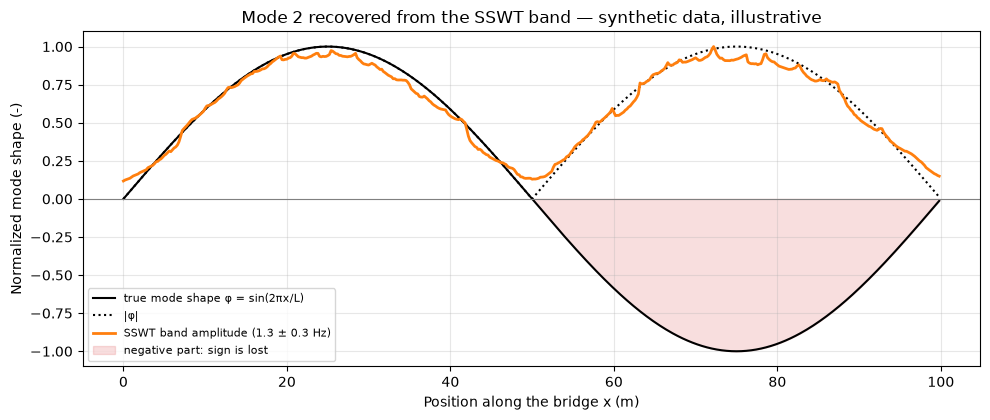

In [5]:
# Mode shape from the SSWT: mean amplitude in the band around the mode frequency
half_band = 0.3                         # half width of the frequency band, Hz
band = np.abs(freqs_ssq - f_mode) <= half_band
amp_band = np.abs(Tx[band]).mean(axis=0)
phi_est = amp_band / amp_band.max()     # normalized to max = 1

rms_abs = np.sqrt(np.mean((phi_est - np.abs(phi_true)) ** 2))
rms_signed = np.sqrt(np.mean((phi_est - phi_true) ** 2))
print(f"RMS error vs |phi|: {rms_abs:.3f}")
print(f"RMS error vs phi (with sign): {rms_signed:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos, phi_true, "k-", lw=1.5, label="true mode shape φ = sin(2πx/L)")
ax.plot(pos, np.abs(phi_true), "k:", lw=1.5, label="|φ|")
ax.plot(pos, phi_est, color="C1", lw=2, label=f"SSWT band amplitude ({f_mode} ± {half_band} Hz)")
ax.fill_between(pos, phi_true, 0, where=phi_true < 0, color="C3", alpha=0.15,
                label="negative part: sign is lost")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("Position along the bridge x (m)")
ax.set_ylabel("Normalized mode shape (-)")
ax.set_title("Mode 2 recovered from the SSWT band — synthetic data, illustrative")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 4.** Amplitud promedio de la SSWT en la banda de 1.3 Hz a lo largo de la posición, comparada con la forma modal verdadera (ilustrativo, datos sintéticos): la curva sigue a $|\phi|$, pero en el tramo de 50 a 100 m, donde la forma real es negativa, sale positiva. Se recupera la forma en valor absoluto y se pierde el signo.

- El error RMS respecto a $|\phi|$ es pequeño; respecto a $\phi$ con signo es grande, porque todo el tramo negativo sale reflejado hacia arriba.
- Para recuperar el signo hace falta otra información (por ejemplo, la fase); la amplitud por sí sola no la tiene.

**Ventajas**

- Funciona con señales cortas y no estacionarias.
- Da frecuencia y posición a la vez.

**Desventajas**

- Para formas modales hay que conocer de antemano la frecuencia del modo.
- La amplitud no tiene signo: la forma modal sale en valor absoluto.
- No separa la respuesta del puente de la del vehículo.

**Artículos:** Dabbaghchian et al. (2025).

> **Nota de fuentes.** La explicación general de cómo funciona la wavelet es conocimiento general, no del artículo. Del artículo vienen: el uso de la SSWT con wavelet madre Morlet analítica y los límites para formas modales (frecuencia conocida de antemano, forma modal absoluta).

[↑ Volver al índice](#indice)